In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit

In [2]:
size = 50
temperature = 2.0
pressure = 1
steps = 10000

In [4]:
lattice = np.random.choice([1, -1], size = (size, size))

In [5]:
@njit
def calculate_energy(lattice, L, J):
    energy = 0
    for i in range(size):
        for j in range(size):
            spin = lattice[i, j]
            neighbors = (
                lattice[(i+1) % size, j] + lattice[i, (j+1) % size] +
                lattice[(i-1) % size, j] + lattice[i, (j-1) % size]
            )
            energy += -pressure * spin * neighbors
    return energy / 2

In [ ]:
@njit
def metropolis_step(lattice, temperature, size, pressure):
    for _ in range(size * size):
        i = np.random.randint(0, size)
        j = np.random.randint(0, size)
        
        spin = lattice[i, j]
        neighbors = (
                lattice[(i+1) % size, j] + lattice[i, (j+1) % size] +
                lattice[(i-1) % size, j] + lattice[i, (j-1) % size]
        )
        dE = 2 * pressure * spin * neighbors
        if dE < 0 or np.random.rand() < np.exp(-dE / temperature):
            lattice[i, j] *= -1 #Переворачиваем спин

In [7]:
energies = []
for _ in range(steps):
    metropolis_step(lattice, temperature, size, pressure)
    energies.append(calculate_energy(lattice, size, pressure))

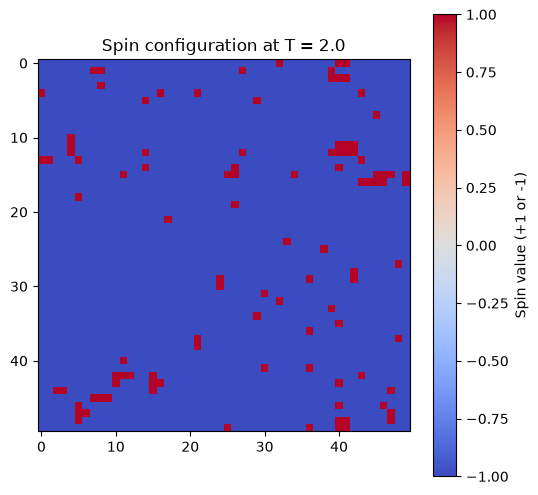

In [8]:
plt.figure(figsize=(6, 6))
plt.imshow(lattice, cmap = 'coolwarm', interpolation='nearest')
plt.title(f"Spin configuration at T = {temperature}")
plt.colorbar(label = "Spin value (+1 or -1)")
plt.show()

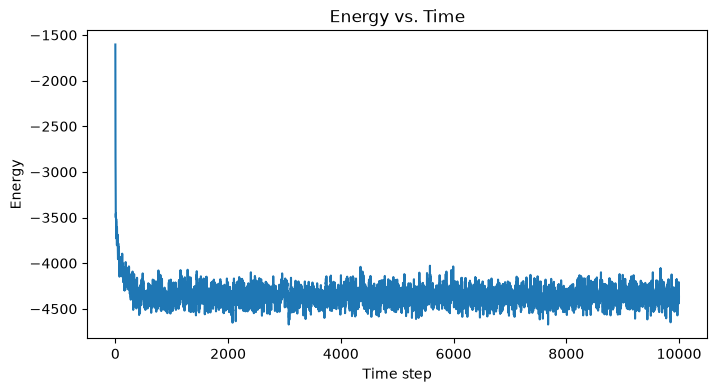

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(energies)
plt.xlabel("Time step")
plt.ylabel("Energy")
plt.title("Energy vs. Time")
plt.show()